In [ ]:
print('abc')

In [82]:
## install libraries for import
try:
    from pip import main as pipmain
except ImportError:
    from pip._internal import main as pipmain

pipmain(["install", 'h5py'])
pipmain(["install", 'numpy'])

## import libraries
import os
import h5py
import numpy as np

## set number of spectra and path to the data files
os.chdir("D:\\LIBS_class\\")   # selecting the directory containing the data files
spectraCount = 200                           # selecting the number of spectra for each sample (maximum of 500)

##########################################
# Train Data
##########################################

trainFile = h5py.File("train.h5",'r')   # training data, unless the filename was changed


Please see https://github.com/pypa/pip/issues/5599 for advice on fixing the underlying issue.
To avoid this problem you can invoke Python with '-m pip' instead of running pip directly.


Defaulting to user installation because normal site-packages is not writeable

Requirement already satisfied: h5py in c:\programdata\anaconda3\lib\site-packages (3.12.1)

Requirement already satisfied: numpy>=1.19.3 in c:\programdata\anaconda3\lib\site-packages (from h5py) (2.1.3)

Please see https://github.com/pypa/pip/issues/5599 for advice on fixing the underlying issue.
To avoid this problem you can invoke Python with '-m pip' instead of running pip directly.


Defaulting to user installation because normal site-packages is not writeable

Requirement already satisfied: numpy in c:\programdata\anaconda3\lib\site-packages (2.1.3)

In [83]:
wavelengths = trainFile["Wavelengths"]
#wavelengths = wavelengths[list(wavelengths.keys())[0]].value
wavelengths = wavelengths[list(wavelengths.keys())[0]][()]
# creates a one-dimensional array (vector) containing the wavelengths
print(wavelengths)

[ 200.          200.02000427  200.03999329 ...  999.97998047 1000.
 1000.02001953]


In [95]:
import time
start = time.perf_counter()

for sample in list(trainFile["Spectra"].keys()):
    tempData = trainFile["Spectra"][sample][()]
    tempData = tempData[:,0:spectraCount]
    if "trainData" not in locals():
        trainData = tempData.transpose()
    else:
        trainData = np.append(trainData, tempData.transpose(), axis = 0)
# creates a two-dimensional array (matrix) containing the training data
# each row represents a single spectrum

trainClass = trainFile["Class"]["1"][()]
for i in range(0,50000,500):
    if i == 0:
        tempClass = trainClass[0:spectraCount]
    else:
        tempClass = np.append(tempClass, trainClass[i:(i+spectraCount)])
trainClass = tempClass
# creates a one-dimensional array (vector) containing the classes corresponding to the spectra in the training dataset
# the order of the classes is the same as the order of the spectra
# if the dataset is reordered (e.g., randomly sampled), make sure that the classes are reordered accordingly
trainFile.close()
del tempClass, tempData, i, sample


end = time.perf_counter()

print(f"Elapsed: {0.001*(end - start) * 1e3:.3f} s")

KeyboardInterrupt: 

In [96]:

##########################################
# Test Data
##########################################

testFile = h5py.File("test.h5",'r')     # testing data, unless the filename was changed

for sample in list(testFile["UNKNOWN"].keys()):
    tempData = testFile["UNKNOWN"][sample][()]
   
    if "testData" not in locals():
        testData = tempData.transpose()
    else:
       testData = np.append(testData, tempData.transpose(), axis = 0)


# creates a two-dimensional array (matrix) containing the testing data
# each row represents a single spectrum
testFile.close()
del tempData, sample, spectraCount
##########################################
# End of loading script
##########################################
# Returns 4 variables -> trainData, trainClass, testData, wavelengths
##########################################

In [98]:
print(testData.shape)
testD1= (testData[:, 0::2] + testData[:, 1::2]) / 2
print(testD1.shape)

(20000, 40002)
(20000, 20001)


In [ ]:
print(trainData.shape)

In [ ]:
import sys
print(sys.getsizeof(trainData)/1000000000)

In [ ]:

trainD1 = (trainData[:, 0::2] + trainData[:, 1::2]) / 2

In [ ]:
print(sys.getsizeof(trainD1)/1000000000)

In [130]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split


#print(trainData.shape)
#print(trainClass.shape)
#print(type(trainData))
#print(type(trainClass))
xtorch= torch.tensor(trainD1, dtype=torch.float32)
ytorch =torch.tensor(trainClass, dtype=torch.int32)
print(type(xtorch))
print(type(ytorch))

yOneHot = torch.zeros((ytorch.size(0), 12), dtype=torch.float32)
yOneHot[torch.arange(ytorch.size(0)), ytorch - 1] = True
print(type(yOneHot))
xtest= torch.tensor(testD1, dtype=torch.float32)

<class 'torch.Tensor'>
<class 'torch.Tensor'>
<class 'torch.Tensor'>


In [3]:
print(type(yOneHot))
print(yOneHot[10000])


#del trainData



<class 'torch.Tensor'>
tensor([0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.])


In [4]:
class LIBS_1D_CNN(nn.Module):
    def __init__(self, input_dim, num_elements):
        super(LIBS_1D_CNN, self).__init__()
        
        self.conv_layers = nn.Sequential(

            # Conv1d z kernel_size=7, na starcie: Szeroki filtr pozwala "zauwazyc" ca;e szerokie piki i ich otoczenie
            
            nn.Conv1d(1, 32, kernel_size=7, stride=1, padding=3),
            
            # BarchNorm1d: Zapobiega problemowi "eksplodujacych" gradientow

            nn.BatchNorm1d(32),
            nn.ReLU(),

            # MaxPoll1d: Redukuje wymiarowosc, zachowujac wazne cechy widma

            nn.MaxPool1d(kernel_size=2),
            
            nn.Conv1d(32, 64, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        
        # Obliczony dynamiczne, 
        self.flattened_size = 128 * (input_dim // 8) 
        
        self.fc_layers = nn.Sequential(
            nn.Linear(self.flattened_size, 512),
            nn.ReLU(),

            # Dropout: Zmniejsza przeuczenie sieci

            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_elements)
        )

    def forward(self, x):
        x = x.unsqueeze(1) # Dodajemy kanał do konwolucji: wymagane
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1) # Spłaszczamy
        x = self.fc_layers(x)
        x=F.sigmoid(x)
            
        return x


In [5]:
import torch
from torch.utils.data import Dataset, DataLoader




class TensorDatasetCustom(Dataset):
    def __init__(self, data_tensor, target_tensor):
        assert data_tensor.size(0) == target_tensor.size(0), \
            "Data i target muszą mieć ten sam rozmiar w pierwszym wymiarze"
        
        self.data = data_tensor
        self.targets = target_tensor

    def __len__(self):
        return self.data.size(0)

    def __getitem__(self, idx):
        x = self.data[idx]
        y = self.targets[idx]
        return x, y


dataset = TensorDatasetCustom(xtorch, yOneHot)

In [6]:
BATCH_SIZE = 128
EPOCHS = 15
LEARNING_RATE = 0.0005

In [7]:


# Podział 80% Trening, 20% Walidacja
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

    # Zostawiamy num_workers=0 (ochrona przed deadlockiem w Windows), dodajemy pin_memory=True - przyspiesza kopiowanie danych z RAM do VRAM
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)

In [8]:
import gc





import torch
import pandas as pd
import numpy as np
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import os
import time
import matplotlib.pyplot as plt
from sklearn import metrics
from torch.optim.lr_scheduler import LambdaLR
from tqdm import tqdm
import warnings

In [ ]:
# Przygotowanie urządzenia i modelu

  

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nTrening uruchomiony na: {device}")
#s1=40002
s1=20001

model = LIBS_1D_CNN(input_dim=s1, num_elements=12).to(device)
    
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    
# Scheduler: Zmniejsza Learning Rate o połowę, jeśli Val Loss nie spada przez 3 epoki
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

best_val_loss = float('inf')

    # Trening właściwy
for epoch in range(EPOCHS):
        start = time.perf_counter()
        model.train()
        running_train_loss = 0.0
        print("start epoch "+str(epoch))
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            running_train_loss += loss.item() * inputs.size(0)
            
        epoch_train_loss = running_train_loss / len(train_dataset)
        
        # Walidacja
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                running_val_loss += loss.item() * inputs.size(0)
                
        epoch_val_loss = running_val_loss / len(val_dataset)
        
        # Pobieranie aktualnego Learning Rate, aby widzieć działanie schedulera
        current_lr = optimizer.param_groups[0]['lr']
        
        print(f"Epoka {epoch+1:02d}/{EPOCHS} | Train Loss (MSE): {epoch_train_loss:.6f} | Val Loss: {epoch_val_loss:.6f} | LR: {current_lr:.6f}")

        # Krok schedulera - na podstawie błędu walidacji
        scheduler.step(epoch_val_loss)

        # Zapis modelu
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            torch.save(model.state_dict(), 'best_libsABC_model_1.pth')
        torch.cuda.empty_cache()
        end = time.perf_counter()
        print(f"Elapsed: {0.001*(end - start) * 1e3:.3f} s")
print("\nZakończono! Najlepszy, ustabilizowany model został zapisany jako 'best_libs_model.pth'.")



In [ ]:
#del trainData

del xtorch
del ytorch

In [ ]:
torch.save(model.state_dict(), 'C:\\Users\\Tomek_\\Desktop\\libs\\t1\\best_libsABC_model_proba3.pth')

In [ ]:
import gc
torch.cuda.empty_cache()
gc.collect()

In [ ]:
import sys
print(sys.getsizeof(train_dataset))

In [ ]:
##to jest niepotrzebne, chyba że chcemy zrobić jakiś podzbiór

import random
from torch.utils.data import Subset, DataLoader
from torchvision.transforms import ToTensor

indices= [random.randint(0, 19999) for _ in range(5000)]
subset = Subset(dataset, indices)

# Create a DataLoader for the subset
dataloader = DataLoader(subset, batch_size=32, shuffle=True)

# Iterate over the DataLoader
for batch_idx, (data, labels) in enumerate(dataloader):
    print(f"Batch {batch_idx + 1}: Data Shape = {data.shape}, Labels Shape = {labels.shape}")

train_size = int(0.8 * len(subset))
val_size = len(subset) - train_size
train_dataset, val_dataset = random_split(subset, [train_size, val_size])

    # Zostawiamy num_workers=0 (ochrona przed deadlockiem w Windows), dodajemy pin_memory=True - przyspiesza kopiowanie danych z RAM do VRAM
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)


In [9]:
import random
from torch.utils.data import Subset, DataLoader
from torchvision.transforms import ToTensor

indices= [random.randint(0, 19999) for _ in range(5000)]
subset = Subset(dataset, indices)



train_size = int(0.8 * len(subset))
val_size = len(subset) - train_size
train_dataset, val_dataset = random_split(subset, [train_size, val_size])

    # Zostawiamy num_workers=0 (ochrona przed deadlockiem w Windows), dodajemy pin_memory=True - przyspiesza kopiowanie danych z RAM do VRAM
train_loaderShap = DataLoader(train_dataset, batch_size=400, shuffle=True, num_workers=0, pin_memory=True)
val_loaderShap = DataLoader(val_dataset, batch_size=25, shuffle=True, num_workers=0, pin_memory=True)

In [ ]:
#niepotrzebne jakieś rysowanie widm
print(dataset[1][0].numpy())
import matplotlib.pyplot as plt
plt.plot(subset[1][0].numpy())

In [ ]:

#jakieś prządki - chyba niepotrzebne
#del trainData
del trainClass
del dataset

In [10]:
try:
    s1=20001    
    ##device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    device = torch.device("cpu")
    modelPath='C:\\Users\\Tomek_\\Desktop\\libs\\t1\\best_libsABC_model_proba1.pth'
    model = LIBS_1D_CNN(input_dim=s1, num_elements=12).to(device)
    model.load_state_dict(torch.load(modelPath, map_location=device))
    print("załadowano model")
except Exception as e:
    print("wystąpił błąd ",e)

załadowano model


In [11]:
#wstępne analizy na zbiorze walidacyjnym
model.eval()
with torch.no_grad():
            suma=0.0;
            ile=0;
            for inputs, targets in val_loader:
                
                inputs, targets = inputs.to(device), targets.to(device)
                
                outputs = model(inputs)          

                o2=outputs.round()
                for x in range(len(outputs)):
                    ile+=1;                   
                    por=o2[x]-targets[x];
                    por=por.cpu()
                    value=por.sum().numpy()
                    suma+=abs(value)
                print('suma aktualnie',suma)
                #break
                #loss = criterion(outputs, targets)
                #running_val_loss += loss.item() * inputs.size(0)
print('suma',suma)
print('ile elementow',ile)

suma aktualnie 1.0
suma aktualnie 1.0
suma aktualnie 1.0
suma aktualnie 1.0
suma aktualnie 1.0
suma aktualnie 1.0
suma aktualnie 1.0
suma aktualnie 1.0
suma aktualnie 1.0
suma aktualnie 1.0
suma aktualnie 1.0
suma aktualnie 2.0
suma aktualnie 2.0
suma aktualnie 2.0
suma aktualnie 2.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 3.0
suma aktualnie 4.0
suma aktualnie 4.0
suma aktualnie 4.0
suma aktualnie 5.0
suma aktualnie 6.0
suma 6.0
ile elementow 4000


In [12]:
#przygotowujemy macierz błędów (zbiór walidacyjny)
##device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")
iteration=0;
model.eval()
with torch.no_grad():
            suma=0.0;            
            for inputs, targets in val_loader:                
                inputs, targets = inputs.to(device), targets.to(device)                
                outputs = model(inputs)    
                o2=outputs.round()
                tar=targets.cpu().numpy();
                oo2=o2.cpu().numpy();                
                if iteration==0:
                    tarAll=tar   
                    outAll=oo2;
                else:
                    tarAll=np.concatenate([tarAll,tar])
                    outAll=np.concatenate([outAll,oo2])                   
                
                iteration+=1;
                
                    

<Axes: >

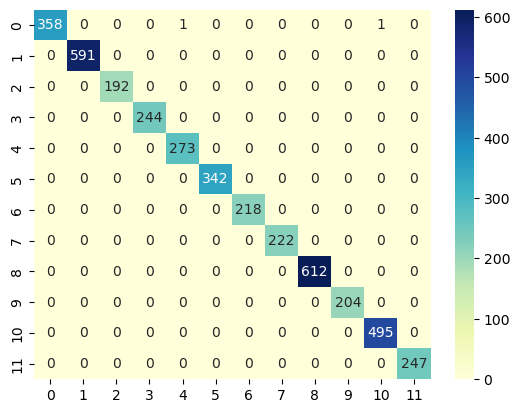

In [13]:
#tu ją wyświetlamy

#print(tarAll.shape)
#print(outAll.shape)
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(outAll.argmax(axis=1), tarAll.argmax(axis=1))
# Plot the confusion matrix
sns.heatmap(cm, annot=True,fmt='d', cmap='YlGnBu')

In [14]:
#a tu analizujemy

correct=0;
for i in range(cm.shape[0]):
    correct+=cm[i][i]
print("poprawna predykcja ", correct, " próbek")
print("błędna predykcja ",tarAll.shape[0]-correct,"próbek")

poprawna predykcja  3998  próbek
błędna predykcja  2 próbek


In [15]:



#przygotowujemy macierz błędów (zbiór treningowy)

iteration=0;
with torch.no_grad():
            suma=0.0;            
            for inputs, targets in train_loader:                
                inputs, targets = inputs.to(device), targets.to(device)                
                outputs = model(inputs)    
                o2=outputs.round()
                tar=targets.cpu().numpy();
                oo2=o2.cpu().numpy();                
                if iteration==0:
                    tarAll=tar   
                    outAll=oo2;
                else:
                    tarAll=np.concatenate([tarAll,tar])
                    outAll=np.concatenate([outAll,oo2])                   
                
                iteration+=1;
                #print(iter)

In [ ]:
#tu ją wyświetlamy  (zbiór treningowy)

#print(tarAll.shape)
#print(outAll.shape)
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(outAll.argmax(axis=1), tarAll.argmax(axis=1))
# Plot the confusion matrix
sns.heatmap(cm, annot=True,fmt='d', cmap='YlGnBu')

In [ ]:
#a tu analizujemy

correct=0;
for i in range(cm.shape[0]):
    correct+=cm[i][i]
print("poprawna predykcja ", correct, " próbek")
print("błędna predykcja ",tarAll.shape[0]-correct,"próbek")

In [ ]:

trainD1 = (trainData[:, 0::2] + trainData[:, 1::2]) / 2



In [ ]:
del trainData
import matplotlib.pyplot as plt

In [ ]:
print(trainD1[0])
trainD2 = (trainD1[:, 0::3] + trainD1[:, 1::3]+trainD1[:, 2::3]) / 3

In [ ]:
print(trainD2[0])

In [ ]:
np.save("C:\\Users\\Tomek_\\Desktop\\libs\\t1\\trainClass.data",trainClass)

In [ ]:
trainD22=np.load("C:\\Users\\Tomek_\\Desktop\\libs\\t1\\trainD2.data.npy")

In [ ]:
x=trainD22[0]
x1=trainD22[1]
print(x.shape)
plt.plot(x)
plt.plot(x1)
plt.xlim(1500,1700)

In [1]:
import numpy as np
trainD1=np.load("C:\\Users\\Tomek_\\Desktop\\libs\\t1\\trainD1.data.npy")
trainClass=np.load("C:\\Users\\Tomek_\\Desktop\\libs\\t1\\trainClass.data.npy")

In [16]:
import shap
#val_loaderShap
batch = next(iter(train_loaderShap))
spectra,_ = batch
spectra.to(device)

tensor([[-2.8247e+01, -2.5478e+01,  4.8299e+01,  ...,  7.4250e+01,
         -4.0796e-01,  4.1646e+00],
        [ 7.9766e+01, -5.3193e+01, -9.6867e+01,  ...,  1.2597e+01,
          4.2185e+01,  1.5817e+01],
        [-1.5234e+02, -1.3282e+02,  4.5710e+01,  ..., -2.5053e+01,
         -9.0031e+01, -2.6712e+01],
        ...,
        [-1.2344e+02, -1.6350e+01,  5.5772e+01,  ..., -2.6123e-02,
         -7.7815e+00,  3.6495e+00],
        [-5.9669e+01, -1.3813e+00,  7.6973e+00,  ..., -1.7201e+01,
          1.3856e+01,  1.6125e+01],
        [ 8.1128e+00, -3.4509e+01, -7.4958e+01,  ...,  3.6873e+01,
          5.8706e+01,  1.8555e+01]])

In [17]:

e = shap.GradientExplainer(model,spectra)


In [18]:
batch1 = next(iter(val_loaderShap))
spectraTest,etTest = batch1
print(spectraTest.shape)

torch.Size([25, 20001])


In [19]:
shap_values = e.shap_values(spectraTest)

In [61]:
from matplotlib import colors
shap_limitM=0.001;
shap_limitP=0.001;
norm=colors.TwoSlopeNorm(vcenter=0, vmin=-shap_limitP, vmax=shap_limitP)

tensor([0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0.])
tensor(6)


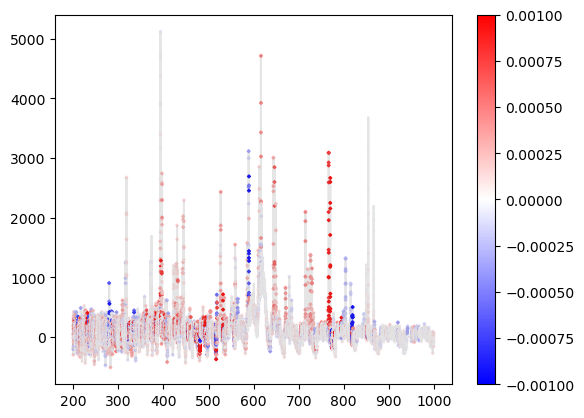

In [93]:
widmoNR=3
temp=shap_values[widmoNR]
zz=np.transpose(temp)
print(etTest[widmoNR])
klasa=np.argmax(etTest[widmoNR])
widmo=spectraTest[widmoNR]
print(klasa)
x=np.arange(0,len(widmo),1)
zz1=zz[klasa]
from scipy.signal import savgol_filter

smoothed = savgol_filter(zz1, window_length=35, polyorder=5)

plt.plot(wavelengths1,widmo,alpha=0.2, c='grey'  )
#norm=colors.TwoSlopeNorm(vcenter=0, vmin=min(smoothed), vmax=max(smoothed))
plt.scatter(
        wavelengths1,widmo,        
        c=smoothed,
        cmap='bwr',
        marker='D',
        s=2,
        norm=norm
    )
plt.colorbar()
#plt.xlim(4000,5000)

In [64]:
print(min(smoothed))
print(max(smoothed))

-0.0024054861809252727
0.007364315861777679


In [ ]:
print(temp.shape)

print(zz.shape)

In [ ]:
print(spectraTest[0].shape)

In [ ]:
plt.plot(zz[10])


In [ ]:
widmoNR=5

from matplotlib import colors
shap_limitM=0.01;
shap_limitP=0.001;
norm=colors.TwoSlopeNorm(vcenter=0, vmin=-shap_limitP, vmax=shap_limitP)

temp=shap_values[widmoNR]
zz=np.transpose(temp)
print(etTest[widmoNR])
klasa=np.argmax(etTest[widmoNR])
widmo=spectraTest[widmoNR]
#plt.plot(zz[klasa])
x=np.arange(0,len(widmo),1)

(20001,)
(20000,)
(2500,) (2500,)


ValueError: x and y must have same first dimension, but have shapes (20001,) and (2500,)

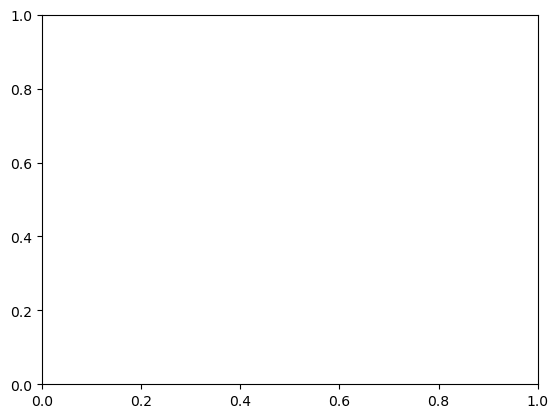

In [88]:

zzk=zz[klasa]
print(zzk.shape)
zzk1=zzk[0:20000]
print(zzk1.shape)
zzSR = (zzk1[0::8]+zzk1[1::8]+zzk1[2::8]+zzk1[3::8] + zzk1[4::8]+zzk1[5::8]+zzk1[6::8]+zzk1[7::8]   )
xN=np.arange(0,20000,8)
print(zzSR.shape,xN.shape)
widmo=widmo[0:20000]
widmo1= (widmo[0::8]+widmo[1::8]+widmo[2::8]+widmo[3::8] + widmo[4::8]+widmo[5::8]+widmo[6::8]+widmo[7::8]   )

x=np.arange(0,len(widmo),8)
plt.plot(wavelengths1,widmo1,alpha=0.2, c='grey'  )
cc=zzSR.flatten(),
print(cc)
w=np.full((zzSR.shape[0]), 7, dtype=int)

plt.scatter(
        wavelengths1,widmo1,        
        c=cc,
        cmap='bwr',
        marker='D',
        s=0.5,
        norm=norm
    )
plt.colorbar()






In [ ]:
x=np.arange(0,len(widmo1),8)
plt.plot(x,widmo1,alpha=0.2, c='grey'  )

In [22]:
cc=zzSR.flatten(),
print(cc)
w=np.full((zzSR.shape[0]), 7, dtype=int)


plt.scatter(
        xN,w,        
        c=cc,
        cmap='bwr',
        marker='D',
        s=2,
        norm=norm
    )
plt.colorbar()

NameError: name 'zzSR' is not defined

In [ ]:


print(w)

tensor([1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])
tensor(0)


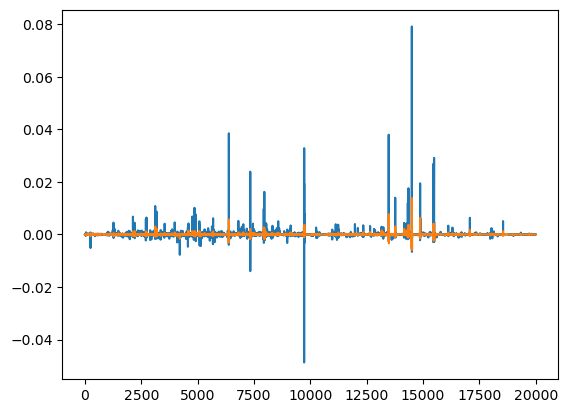

In [33]:
widmoNR=12

temp=shap_values[widmoNR]
zz=np.transpose(temp)
print(etTest[widmoNR])
klasa=np.argmax(etTest[widmoNR])
print(klasa)
widmo=spectraTest[widmoNR]
#plt.plot(zz[klasa])
x=np.arange(0,len(widmo),1)

from scipy.signal import savgol_filter

smoothed = savgol_filter(zz[klasa], window_length=21, polyorder=3)

plt.plot(zz[klasa])
plt.plot(smoothed)

In [86]:
print(wavelengths.shape)
#wavelengths=wavelengths[0:39999]
wavelengths1 = (wavelengths[0::2] + wavelengths[ 1::2]) / 2
print(wavelengths1.shape)
print(smoothed.shape)

(40002,)
(20001,)
(20001,)


In [103]:
o=model(xtest)

RuntimeError: [enforce fail at alloc_cpu.cpp:121] data. DefaultCPUAllocator: not enough memory: you tried to allocate 51202560000 bytes.

In [104]:
testn_loader = DataLoader(xtest, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)

In [105]:
iteration=0;
with torch.no_grad():
            suma=0.0;            
            for inputs in testn_loader:                
                inputs = inputs.to(device)            
                outputs = model(inputs) 

KeyboardInterrupt: 

In [109]:
device = torch.device("cpu")
print(BATCH_SIZE)
iteration=0;
model.eval()
with torch.no_grad():
            suma=0.0;            
            for inputs in testn_loader :                
                inputs= inputs.to(device)               
                outputs = model(inputs)    
                o2=outputs.round()
               
                oo2=o2.cpu().numpy();                
                if iteration==0:
                   
                    outAll=oo2;
                else:
                    
                    outAll=np.concatenate([outAll,oo2])                   
                
                iteration+=1;
                print(iteration)



128
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157


In [113]:
print(outAll.shape)

ww=np.sum(outAll,axis=0)
print(ww)

(20000, 12)
[1.938e+03 2.746e+03 4.220e+02 1.147e+03 1.990e+03 3.454e+03 3.220e+02
 1.704e+03 3.579e+03 1.202e+03 1.735e+03 3.000e+00]


In [131]:
import numpy as np

data = np.genfromtxt('C:\\Users\\Tomek_\\Desktop\\libs\\test_labels.csv', delimiter=',')
print(data.shape)

ytest =torch.tensor(data, dtype=torch.int32)
#print(type(xtorch))
#print(type(ytorch))

yTestOneHot = torch.zeros((ytest.size(0), 12), dtype=torch.float32)
yTestOneHot[torch.arange(ytest.size(0)), ytest - 1] = True

datasetTest = TensorDatasetCustom(xtest, yTestOneHot)
print(yTestOneHot)

testn_loader = DataLoader(datasetTest, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)



(20000,)
tensor([[0., 0., 0.,  ..., 0., 1., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [1., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 1., 0.,  ..., 0., 0., 0.]])


In [132]:
#przygotowujemy macierz błędów (zbiór testowy)
##device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")
iteration=0;
model.eval()
with torch.no_grad():
            suma=0.0;            
            for inputs, targets in testn_loader:                
                inputs, targets = inputs.to(device), targets.to(device)                
                outputs = model(inputs)    
                o2=outputs.round()
                tar=targets.cpu().numpy();
                oo2=o2.cpu().numpy();                
                if iteration==0:
                    tarAll=tar   
                    outAll=oo2;
                else:
                    tarAll=np.concatenate([tarAll,tar])
                    outAll=np.concatenate([outAll,oo2])                   
                
                iteration+=1;
                print(iteration)

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157


In [133]:
print(yTestOneHot)

tensor([[0., 0., 0.,  ..., 0., 1., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [1., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 1., 0.,  ..., 0., 0., 0.]])


<Axes: >

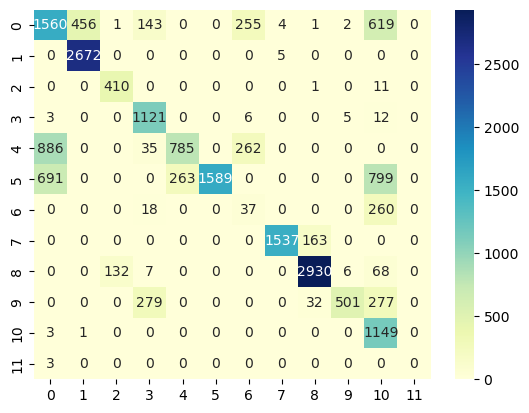

In [134]:
#tu ją wyświetlamy
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(outAll.argmax(axis=1), tarAll.argmax(axis=1))
# Plot the confusion matrix
sns.heatmap(cm, annot=True,fmt='d', cmap='YlGnBu')

In [136]:
#a tu analizujemy

correct=0;
for i in range(cm.shape[0]):
    correct+=cm[i][i]
print("poprawna predykcja ", correct, " próbek")
print("błędna predykcja ",tarAll.shape[0]-correct,"próbek")
print('accuracy ', correct/tarAll.shape[0])

poprawna predykcja  14291  próbek
błędna predykcja  5709 próbek
accuracy  0.71455
